In [2]:
# Install SHAP (not pre-installed in Google Colab)
!pip install -q shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (make sure the CSV is uploaded to your Colab files)
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 1. Basic Data Cleaning
# Remove customerID because a random ID cannot predict behavior
df = df.drop(columns=['customerID'])

# TotalCharges has hidden blank spaces (" ") for brand new customers.
# Convert them to numbers and replace blanks with 0.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# Convert target column 'Churn' from text ('Yes'/'No') to numbers (1/0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 2. Feature Engineering
# Group customer tenure into clear stages (new vs. loyal customers)
df['Tenure_Group'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-1 Year', '1-2 Years', '2-4 Years', '4+ Years']
)

# Count how many extra services each customer uses (more services = less likely to leave)
addon_services = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
df['Total_Services'] = (df[addon_services] == 'Yes').sum(axis=1)

print("Data cleaned successfully! Dataset shape:", df.shape)
df.head()

Data cleaned successfully! Dataset shape: (7043, 22)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Group,Total_Services
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-1 Year,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,0,2-4 Years,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-1 Year,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,2-4 Years,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-1 Year,0


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# 1. Convert text columns into numeric dummy columns (One-Hot Encoding)
df_encoded = pd.get_dummies(df, drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# 2. Split into Training (80%) and Testing (20%) sets
# stratify=y keeps the exact same ~26.5% churn ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scale numeric columns so large numbers (like TotalCharges) don't dominate
scaler = StandardScaler()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Total_Services']

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# 4. Handle Class Imbalance with SMOTE
# Only apply SMOTE to training data so test data stays completely realistic
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# 5. Train the XGBoost Classifier
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train_balanced, y_train_balanced)
print("Model training complete!")

Model training complete!


Model ROC-AUC Score: 0.8346

--- Classification Report (Threshold = 0.35) ---
              precision    recall  f1-score   support

           0       0.92      0.69      0.79      1035
           1       0.49      0.83      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.70      1409
weighted avg       0.81      0.73      0.74      1409



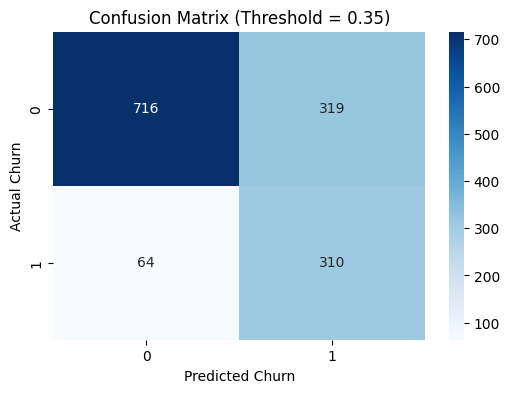

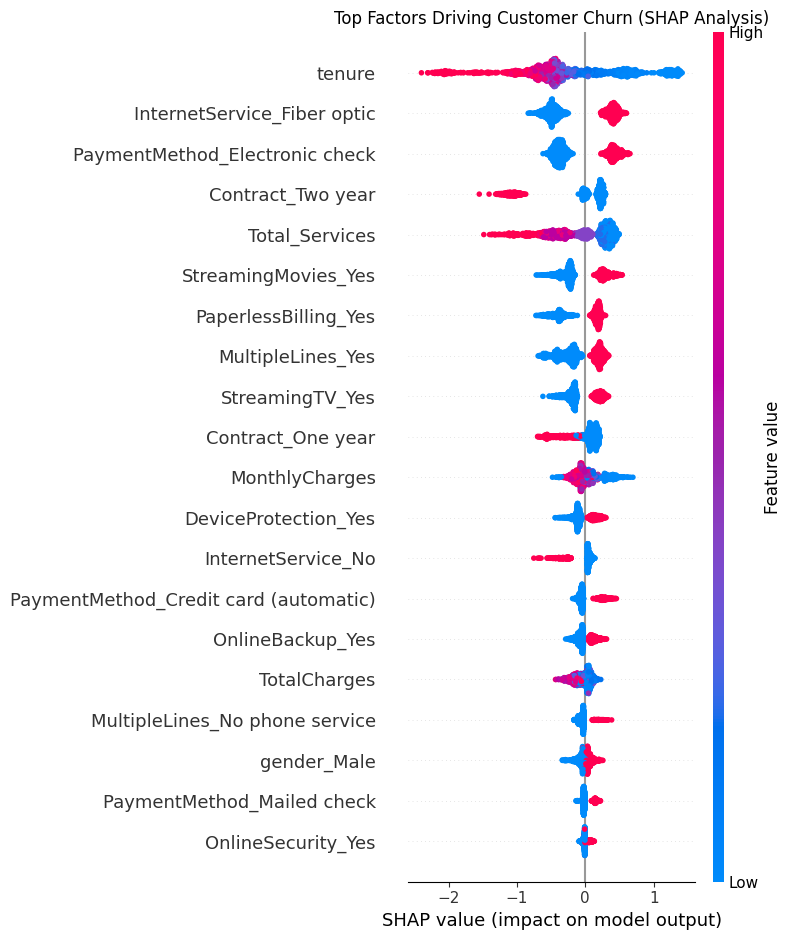

In [4]:
import shap
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Predict Churn Probabilities
churn_probabilities = model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, churn_probabilities)
print(f"Model ROC-AUC Score: {auc_score:.4f}\n")

# 2. Apply Business Threshold (0.35 instead of default 0.50)
# Why? In telecom, missing a customer who is about to leave is much more expensive
# than accidentally offering a retention discount to a happy customer.
custom_threshold = 0.35
predictions = (churn_probabilities >= custom_threshold).astype(int)

print(f"--- Classification Report (Threshold = {custom_threshold}) ---")
print(classification_report(y_test, predictions))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix (Threshold = {custom_threshold})')
plt.xlabel('Predicted Churn')
plt.ylabel('Actual Churn')
plt.show()

# 3. Explain Predictions with SHAP
# Shows which features push a customer toward leaving (red) or staying (blue)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Top Factors Driving Customer Churn (SHAP Analysis)")
plt.tight_layout()

# Save the plot so you can upload it directly to your GitHub README
plt.savefig('shap_churn_summary.png', dpi=300, bbox_inches='tight')
plt.show()